# Vaizdų atpažinimas: tikros ir DI sugeneruotos naujienų nuotraukos

Uždavinys: nustatyti, ar naujienų nuotrauka tikra, ar sugeneruota dirbtinio intelekto. Tai nauja netikrų naujienų forma: sugeneruotos „naujienų nuotraukos“, kurios atrodo kaip tikros.

Duomenys: **MiRAGeNews** (Huang et al., EMNLP Findings 2024). Tikros nuotraukos paimtos iš naujienų leidėjų, o netikros sugeneruotos difuzijos modeliais pagal naujienų antraštes. Naudojamas **MobileNetV2**, iš anksto išmokytas su ImageNet nuotraukomis (perkeliamasis mokymas), ir palyginami du būdai paduoti vaizdą tinklui:

1. **Sumažintas vaizdas**: visas vaizdas suspaudžiamas iki 224 × 224 pikselių (įprastas būdas).
2. **Originali raiška**: mokoma su atsitiktinėmis 224 × 224 dalimis originaliu dydžiu, o tikrinama su visu vaizdu originaliu dydžiu. Taip išlieka smulkūs pikselių pėdsakai, kuriuos palieka generatorius ir kuriuos sumažinimas ištrina.

Keras veikia su PyTorch backend, todėl mokoma su GPU.

In [1]:
import os, io, time, warnings
os.environ["KERAS_BACKEND"] = "torch"  # turi buti nustatyta pries importuojant keras
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib, keras, keras_hub, torch
from pathlib import Path
from PIL import Image, ImageFilter
from keras import layers
from huggingface_hub import snapshot_download
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

DATA = Path("../data/mirage_news")
FIG = Path("../report/figures"); FIG.mkdir(parents=True, exist_ok=True)
MODELS = Path("../models")
SIZE = 224
MODES = {"resize": "resized to 224", "native": "native resolution"}  # MobileNetV2 variantai
NAMES = {**MODES, "clip": "CLIP + linear"}
warnings.filterwarnings("ignore", message="`input_shape` is undefined")  # ImageNet svoriai tinka bet kokiam dydziui, ispejimas nesvarbus

## 1. Duomenys
Mokymui 10 000 vaizdų, validacijai 2 500, o trys testo rinkiniai po 500. Kiekviename rinkinyje pusė vaizdų tikri (`label` 0), pusė sugeneruoti (`label` 1).

| Rinkinys | Tikros nuotraukos | Sugeneruoti vaizdai | Ar matyta mokant |
|---|---|---|---|
| train, validation | The New York Times | Midjourney | |
| test1 | The New York Times | Midjourney | tas pats šaltinis |
| test4 | BBC | Stable Diffusion XL | kitas leidėjas ir generatorius |
| test5 | CNN | Stable Diffusion XL | kitas leidėjas ir generatorius |

Du testo rinkiniai su DALL·E vaizdais neatsisiųsti, nes kitą generatorių jau tikrina test4 ir test5. Vaizdai laikomi atmintyje kaip JPEG baitai (mokymo rinkinys apie 650 MB) ir išskleidžiami tik paduodant tinklui, nes išskleisti 10 000 vaizdų užimtų kelis GB.

In [2]:
def load(name):
    df = pd.read_parquet(DATA / f"{name}-00000-of-00001.parquet", columns=["image", "label"])
    return [d["bytes"] for d in df["image"]], df["label"].to_numpy()

def open_rgb(b):
    return Image.open(io.BytesIO(b)).convert("RGB")  # keli vaizdai PNG arba nespalvoti

train_x, train_y = load("train")
SETS = {"validation": "validation", "test1 NYT / Midjourney": "test1_nyt_mj",
        "test4 BBC / SDXL": "test4_bbc_sdxl", "test5 CNN / SDXL": "test5_cnn_sdxl"}
sets = {name: load(file) for name, file in SETS.items()}

Prieš mokant patikrinta, kuo tikri ir netikri vaizdai skiriasi ne turiniu, o failu. Jei toks skirtumas yra, tinklas gali išmokti jį, o ne generatoriaus požymius.

In [3]:
def jpeg_table(b):  # JPEG kvantavimo lenteles vidurkis: kuo didesnis, tuo stipriau suspausta
    im = Image.open(io.BytesIO(b))
    return np.mean(im.quantization[0]) if im.format == "JPEG" else np.nan

rows = {}
for name, (x, y) in {"train": (train_x, train_y), **sets}.items():
    q = np.array([jpeg_table(b) for b in x])
    size = pd.Series([Image.open(io.BytesIO(b)).size for b in x])  # skaito tik antraste, ne visa vaizda
    rows[name] = {"images": len(y), "fake share": y.mean(),
                  "real: JPEG table mean (median)": np.nanmedian(q[y == 0]), "fake: JPEG table mean (median)": np.nanmedian(q[y == 1]),
                  "fake: distinct JPEG tables": len(np.unique(q[y == 1])),
                  "real: most common size": size[y == 0].mode()[0], "fake: most common size": size[y == 1].mode()[0],
                  "side under 224 px": int(size.map(min).lt(SIZE).sum())}
pd.DataFrame(rows).T

,images,fake share,real: JPEG table mean (median),fake: JPEG table mean (median),fake: distinct JPEG tables,real: most common size,fake: most common size,side under 224 px
train,10000,0.5,44.8125,29.03125,1,"(600, 400)","(600, 400)",1024
validation,2500,0.5,44.8125,29.03125,1,"(600, 400)","(600, 400)",154
test1 NYT / Midjourney,500,0.5,44.8125,29.03125,1,"(600, 330)","(600, 330)",0
test4 BBC / SDXL,500,0.5,23.078125,29.03125,1,"(1024, 576)","(1024, 1024)",0
test5 CNN / SDXL,500,0.5,29.03125,29.03125,1,"(1100, 619)","(1024, 1024)",0


Pastebėti du dalykai:

- **Visi sugeneruoti vaizdai išsaugoti su ta pačia JPEG kvantavimo lentele**, o tikros nuotraukos turi kiekvieno leidėjo savo suspaudimą (dažniausiai stipresnį). Tinklas galėtų išmokti „šis JPEG nustatymas reiškia netikrą“ vietoj generatoriaus požymių. Todėl mokant kiekvienas vaizdas suspaudžiamas iš naujo atsitiktine kokybe (2 skyrius). Tokį pat šališkumą kituose duomenų rinkiniuose aprašė Grommelt et al. (2024, „Fake or JPEG?“).
- Mokymo ir test1 rinkiniuose sugeneruoti vaizdai sumažinti iki tokio pat dydžio kaip tikros nuotraukos, todėl dydis klasių neišduoda. Test4 ir test5 rinkiniuose visi sugeneruoti vaizdai yra 1024 × 1024 kvadratai, o tikros nuotraukos 16:9. Suspaudus viską į 224 × 224, tikros nuotraukos būtų suplotos, o sugeneruoti vaizdai ne. Tai dar viena priežastis tikrinti originaliu dydžiu.

Mokymo vaizdų pavyzdžiai (viršuje tikros nuotraukos, apačioje sugeneruoti vaizdai):

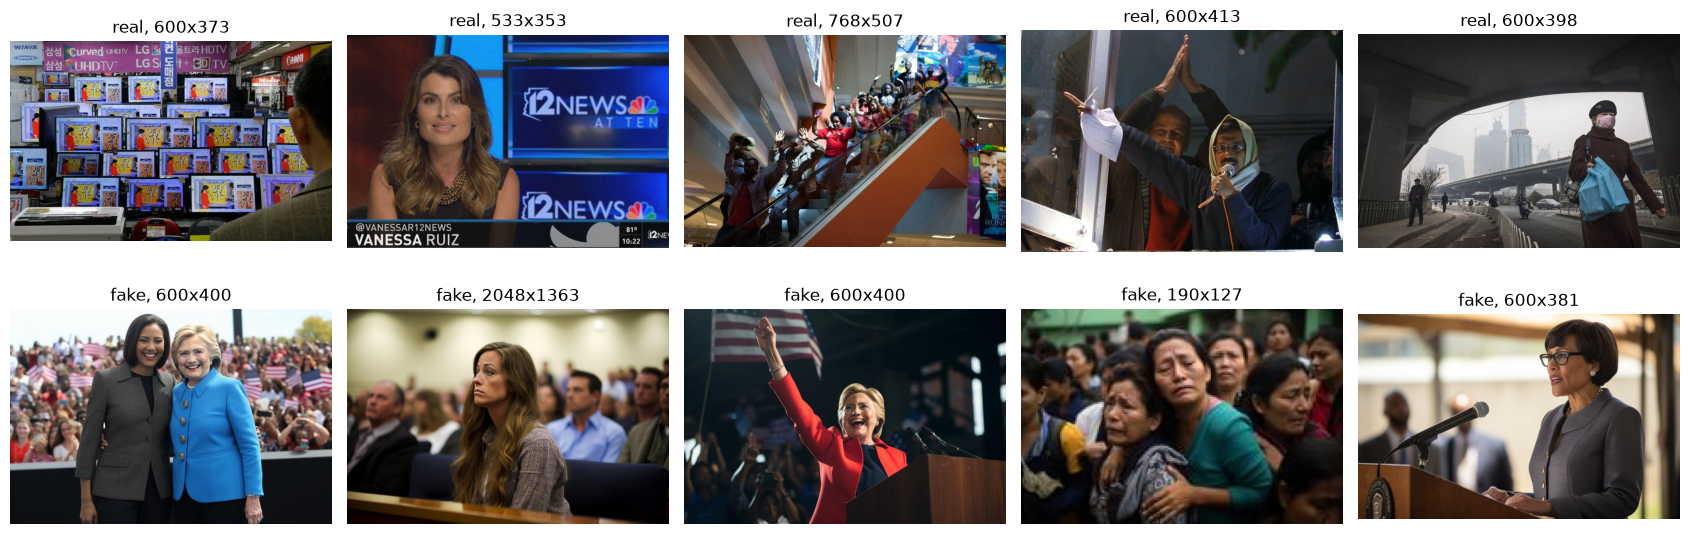

In [4]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(2, 5, figsize=(17, 6))
for row, label in zip(axes, (0, 1)):
    for ax, j in zip(row, rng.choice(np.flatnonzero(train_y == label), 5, replace=False)):
        im = open_rgb(train_x[j])
        ax.imshow(im); ax.set_title(f"{('real', 'fake')[label]}, {im.width}x{im.height}"); ax.axis("off")
plt.tight_layout(); plt.savefig(FIG / "img_examples.png", dpi=110); plt.show()

## 2. Duomenų paruošimas

Abu modeliai gauna tą patį 224 × 224 vaizdą, tik skirtingai paruoštą:

- **Sumažintas vaizdas:** visas vaizdas suspaudžiamas iki 224 × 224, nepaisant proporcijų.
- **Originali raiška:** mokant iš vaizdo iškerpama atsitiktinė 224 × 224 dalis be jokio mastelio keitimo. Tikrinant tinklui paduodamas visas vaizdas originaliu dydžiu: MobileNetV2 sudarytas tik iš konvoliucijų, o gale imamas vidurkis per visą vaizdą, todėl tinka bet koks dydis. Vaizdai, kurių kraštinė mažesnė nei 224 pikseliai, papildomi juodu kraštu, o ne didinami, kad pikseliai nebūtų suglodinti.

Mokymo vaizdai keičiami atsitiktinai (augmentacija), kad tinklas mokytųsi vaizdo savybių, o ne konkrečių vaizdų:

| Pakeitimas | Tikimybė | Kodėl |
|---|---|---|
| Apvertimas horizontaliai | 50 % | veidrodinis vaizdas nekeičia, ar jis tikras |
| Lengvas suliejimas (σ 0,1-1) | 20 % | kad tinklas nepasikliautų vien ryškiausiais pikselių pėdsakais |
| Pakartotinis JPEG suspaudimas (kokybė 60-100) | 100 % | panaikina vienodo JPEG nustatymo užuominą; socialiniai tinklai nuotraukas irgi suspaudžia iš naujo |

Priartinimas ir pasukimas nenaudojami: jie perskaičiuoja pikselius ir suglodina būtent tą triukšmą, kurį tinklas turi pamatyti. Validacijos ir testo vaizdai nekeičiami.

In [5]:
def pad(im):  # mazus vaizdus papildom juodu krastu, kad nereiktu didinti
    if im.width >= SIZE and im.height >= SIZE:
        return im
    out = Image.new("RGB", (max(im.width, SIZE), max(im.height, SIZE)))
    out.paste(im)
    return out

def resave(im, rng):  # visi netikri saugoti vienodu JPEG nustatymu, todel kiekviena mokymo vaizda suspaudziam is naujo atsitiktine kokybe
    buf = io.BytesIO()
    im.save(buf, "JPEG", quality=int(rng.integers(60, 101)))
    return Image.open(buf).convert("RGB")

def augment(im, rng):
    if rng.random() < 0.5:
        im = im.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
    if rng.random() < 0.2:
        im = im.filter(ImageFilter.GaussianBlur(rng.uniform(0.1, 1.0)))
    return resave(im, rng)

class Images(keras.utils.PyDataset):
    def __init__(self, x, y, mode, train=False, batch_size=32):
        super().__init__(workers=4)  # vaizdus isskleidzia 4 gijos, kol GPU mokosi
        self.x, self.y, self.mode, self.train, self.batch_size = x, y, mode, train, batch_size
        self.epoch = 0
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.x) / self.batch_size))

    def on_epoch_end(self):
        self.epoch += 1
        self.order = np.random.default_rng(self.epoch).permutation(len(self.x)) if self.train else np.arange(len(self.x))

    def prepare(self, im, rng):
        if self.mode == "resize":
            im = im.resize((SIZE, SIZE), Image.BILINEAR)
        else:
            im = pad(im)
            if self.train:  # atsitiktine 224x224 dalis, pikseliai nekeiciami
                left, top = rng.integers(0, im.width - SIZE + 1), rng.integers(0, im.height - SIZE + 1)
                im = im.crop((left, top, left + SIZE, top + SIZE))
        if self.train:
            im = augment(im, rng)
        return np.asarray(im, dtype="float32")

    def __getitem__(self, i):
        rng = np.random.default_rng([self.epoch, i])  # ta pati paketo atsitiktinybe nepriklausomai nuo giju eiles
        idx = self.order[i * self.batch_size:(i + 1) * self.batch_size]
        images = np.stack([self.prepare(open_rgb(self.x[j]), rng) for j in idx])
        return images, self.y[idx, None].astype("float32")

def batches(x, y, mode, train=False):
    return Images(x, y, mode, train, batch_size=32 if mode == "resize" or train else 1)  # originalaus dydzio vaizdai skirtingu dydziu, todel po viena

Ką mato kiekvienas modelis. Raudonas kvadratas kairėje yra viena 224 × 224 dalis, kurią mato originalios raiškos modelis; viduryje tas pats vaizdas, sumažintas iki 224 × 224.

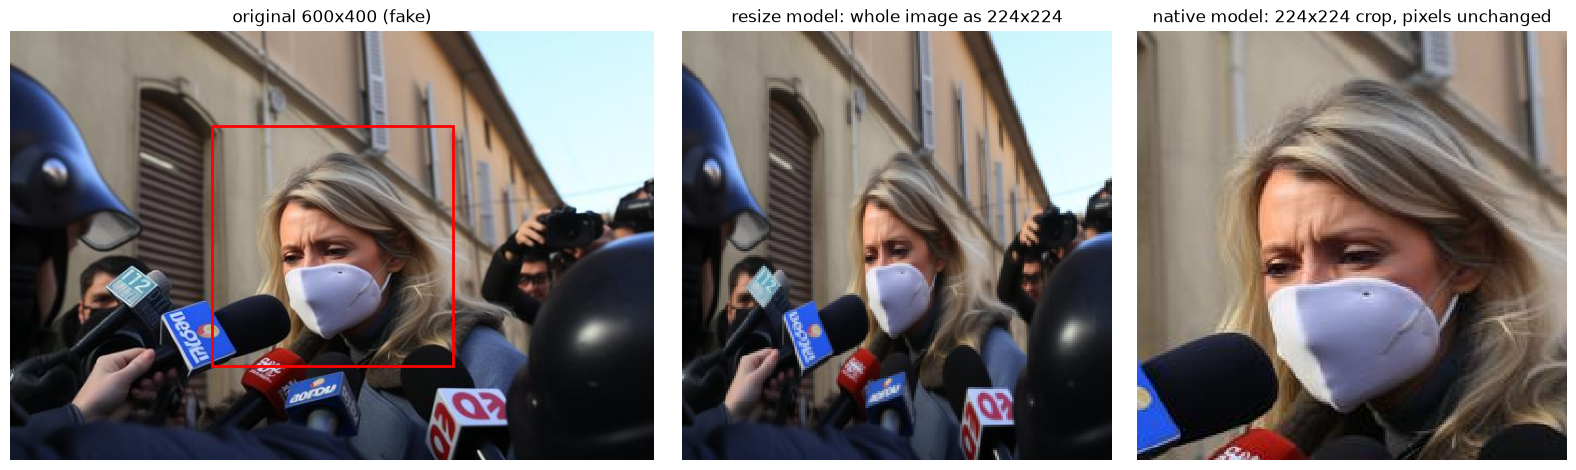

In [6]:
j = next(j for j in np.flatnonzero(train_y == 1) if Image.open(io.BytesIO(train_x[j])).size == (600, 400))
im = open_rgb(train_x[j])
left, top = (im.width - SIZE) // 2, (im.height - SIZE) // 2
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios": [im.width / im.height, 1, 1]})
axes[0].imshow(im); axes[0].add_patch(plt.Rectangle((left, top), SIZE, SIZE, fill=False, ec="red", lw=2))
axes[0].set_title(f"original {im.width}x{im.height} (fake)")
axes[1].imshow(im.resize((SIZE, SIZE), Image.BILINEAR), interpolation="nearest"); axes[1].set_title("resize model: whole image as 224x224")
axes[2].imshow(im.crop((left, top, left + SIZE, top + SIZE)), interpolation="nearest"); axes[2].set_title("native model: 224x224 crop, pixels unchanged")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.savefig(FIG / "img_model_input.png", dpi=110, bbox_inches="tight"); plt.show()

## 3. Modeliai

### 3.1 MobileNetV2

Abiejų MobileNetV2 modelių architektūra ta pati, skiriasi tik įvesties dydis (224 × 224 arba bet koks):

| Sluoksnis | Paskirtis |
|---|---|
| Įvestis | RGB vaizdas, pikseliai 0-255 |
| Rescaling | perskaičiuoja pikselius į intervalą nuo -1 iki 1, kokio tikisi MobileNetV2 |
| MobileNetV2 (ImageNet svoriai) | konvoliucinis tinklas, išmokytas atpažinti objektus 1,4 mln. ImageNet nuotraukų; iš vaizdo išskiria 1 280 požymių žemėlapių |
| GlobalAveragePooling2D | kiekvieno požymio vidurkis per visą vaizdą, todėl įvesties dydis gali būti bet koks |
| Dropout 0,3 | mokant atsitiktinai išjungia 30 % požymių, kad tinklas neįsimintų mokymo vaizdų |
| Dense 1, sigmoid | tikimybė, kad vaizdas sugeneruotas |

Mokoma dviem etapais:

1. MobileNetV2 užšaldytas, mokomas tik paskutinis sluoksnis. Adam, mokymosi greitis 1e-3, iki 10 epochų.
2. Atitirpdomi viršutiniai 30 MobileNetV2 sluoksnių ir mokoma toliau su 100 kartų mažesniu greičiu (1e-5), iki 10 epochų, kad ImageNet svoriai būtų tik pakoreguoti, o ne sugadinti.

Abiem etapais nuostolių funkcija yra binary cross-entropy, paketo dydis 32, o mokymas sustabdomas, kai validacijos accuracy 2 epochas nebekyla, ir grąžinami geriausi svoriai. BatchNorm sluoksniai visą laiką naudoja ImageNet statistiką. Originalios raiškos modelio validacija atliekama su visais vaizdais originaliu dydžiu.

In [7]:
def build(shape):
    base = keras.applications.MobileNetV2(input_shape=shape, include_top=False, weights="imagenet")
    base.trainable = False
    inputs = keras.Input(shape)
    x = layers.Rescaling(1 / 127.5, offset=-1)(inputs)
    x = base(x, training=False)  # BatchNorm lieka su ImageNet statistika ir atitirpdzius
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    return keras.Model(inputs, layers.Dense(1, activation="sigmoid")(x)), base

def train(mode):
    path, hist_path = MODELS / f"mobilenetv2_{mode}.keras", MODELS / f"mobilenetv2_{mode}_history.csv"
    if path.exists():
        return keras.saving.load_model(path, compile=False), pd.read_csv(hist_path)  # tik spejimams, optimizatoriaus nereikia
    keras.utils.set_random_seed(42)  # kad perleidus gautusi tie patys svoriai
    model, base = build((SIZE, SIZE, 3) if mode == "resize" else (None, None, 3))
    data, val = batches(train_x, train_y, mode, train=True), batches(*sets["validation"], mode)
    hist = []
    for stage, lr in [("frozen", 1e-3), ("fine-tuned", 1e-5)]:
        if stage == "fine-tuned":
            base.trainable = True
            for layer in base.layers[:-30]:  # atitirpdom tik virsutinius 30 sluoksniu
                layer.trainable = False
        model.compile(keras.optimizers.Adam(lr), "binary_crossentropy", metrics=["accuracy"])
        start = time.time()
        h = model.fit(data, validation_data=val, epochs=10, verbose=2,
                      callbacks=[keras.callbacks.EarlyStopping("val_accuracy", mode="max", patience=2, restore_best_weights=True)])
        hist.append(pd.DataFrame(h.history).assign(stage=stage, stage_minutes=(time.time() - start) / 60))
    model.save(path)
    hist = pd.concat(hist, ignore_index=True); hist.to_csv(hist_path, index=False)
    return model, hist

models, hists = {}, {}
for mode in MODES:
    models[mode], hists[mode] = train(mode)
models["native"].summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, None, None, 3)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, None, None, 3)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, None, None,     │     2,257,984 │
│ (Functional)                    │ 1280)                  │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,527,681 (5.83 MB)

 Non-trainable params: 731,584 (2.79 MB)

### 3.2 CLIP požymiai ir tiesinis klasifikatorius

Trečias modelis tinklo nemoko visai. **CLIP ViT-L/14** yra OpenAI vaizdų ir tekstų modelis, išmokytas su 400 mln. vaizdų ir jų aprašymų porų. Jis lieka užšaldytas, o kiekvienas vaizdas paverčiamas 768 skaičių vektoriumi (požymiais). Ant šių požymių mokoma tik logistinė regresija.

Ojha et al. (2023, „Towards Universal Fake Image Detectors“) parodė, kad toks būdas geriau tinka nematytiems generatoriams: specialiai išmokytas tinklas „tikrą“ klasę ima laikyti viskuo, kas nepanašu į mokymo netikrus vaizdus, o CLIP požymiai nebuvo mokyti atskirti tikrų ir netikrų, todėl nėra pritaikyti vienam generatoriui. MiRAGeNews autoriai irgi naudojo užšaldytą CLIP tipo modelį su tiesiniu sluoksniu.

- Vaizdai paruošiami taip, kaip mokant CLIP: iškerpamas centrinis kvadratas ir sumažinamas iki 224 × 224.
- Mokymo vaizdai prieš tai vieną kartą suspaudžiami iš naujo atsitiktine JPEG kokybe, kaip ir MobileNetV2 mokyme.
- Požymių vektoriai sunormuojami iki ilgio 1, nes CLIP vektoriai lyginami pagal kryptį.
- Logistinės regresijos stiprumas C parenkamas pagal validacijos accuracy iš 0,1, 1, 10 ir 100.

Požymiai išsaugomi `models/clip_vit_l14_features.npz`, modelis `models/clip_logreg.joblib`.

In [8]:
CLIP_FEATS, CLIP_LR = MODELS / "clip_vit_l14_features.npz", MODELS / "clip_logreg.joblib"
if CLIP_FEATS.exists():
    feats = dict(np.load(CLIP_FEATS))
else:
    clip_dir = snapshot_download("keras/clip_vit_large_patch14")  # ~1,7 GB, atsisiuncia tik pirma karta
    clip = keras_hub.models.CLIPBackbone.from_preset(clip_dir)
    to_clip = keras_hub.layers.CLIPImageConverter.from_preset(clip_dir)  # centrinis kvadratas, 224x224, CLIP spalvu normavimas

    def embed(x, train=False):
        rng, out = np.random.default_rng(0), []
        for i in range(0, len(x), 32):
            ims = [open_rgb(b) for b in x[i:i + 32]]
            if train:
                ims = [resave(im, rng) for im in ims]
            batch = keras.ops.stack([to_clip(np.asarray(im, dtype="float32")) for im in ims])
            with torch.no_grad():  # tik skaiciuojam, gradientu nereikia, kitaip netelpa i GPU
                out.append(keras.ops.convert_to_numpy(clip.get_vision_embeddings(batch)))
        e = np.concatenate(out)
        return e / np.linalg.norm(e, axis=1, keepdims=True)

    feats = {"train": embed(train_x, train=True), **{file: embed(sets[name][0]) for name, file in SETS.items()}}
    np.savez(CLIP_FEATS, **feats)
    del clip

if CLIP_LR.exists():
    logreg = joblib.load(CLIP_LR)
else:
    fits = {c: LogisticRegression(C=c, max_iter=5000).fit(feats["train"], train_y) for c in (0.1, 1, 10, 100)}
    print({c: round(m.score(feats["validation"], sets["validation"][1]), 4) for c, m in fits.items()})
    logreg = max(fits.values(), key=lambda m: m.score(feats["validation"], sets["validation"][1]))  # stipruma renkames pagal validacija
    joblib.dump(logreg, CLIP_LR)
print("C =", logreg.C, " train features:", feats["train"].shape)

C = 100  train features: (10000, 768)


## 4. Mokymo eiga
MobileNetV2 modelių accuracy per epochas:

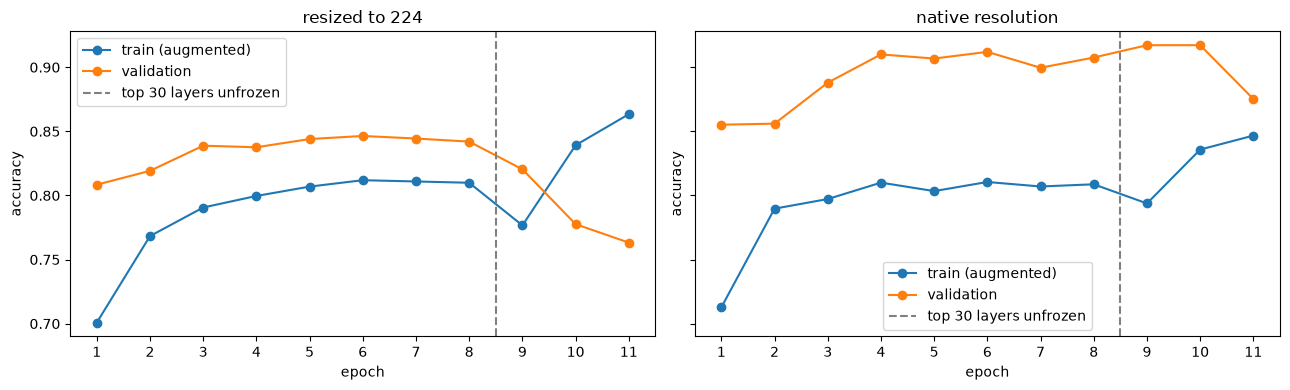

epochs  best_val_accuracy  minutes
model  stage                                         
resize frozen           8              0.846    6.590
       fine-tuned       3              0.820    2.366
native frozen           8              0.912   34.987
       fine-tuned       3              0.917   11.111

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (mode, hist) in zip(axes, hists.items()):
    epochs = np.arange(1, len(hist) + 1)
    ax.plot(epochs, hist["accuracy"], "o-", label="train (augmented)")
    ax.plot(epochs, hist["val_accuracy"], "o-", label="validation")
    ax.axvline((hist["stage"] == "frozen").sum() + 0.5, color="gray", ls="--", label="top 30 layers unfrozen")
    ax.set(title=MODES[mode], xlabel="epoch", ylabel="accuracy", xticks=epochs); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "img_history.png", dpi=120); plt.show()
pd.concat(hists, names=["model", "row"]).groupby(["model", "stage"], sort=False).agg(
    epochs=("accuracy", "size"), best_val_accuracy=("val_accuracy", "max"), minutes=("stage_minutes", "first")).round(3)

Abiem MobileNetV2 modeliams validacijos accuracy didesnis nei mokymo, nes mokymo vaizdai keičiami (suliejami, suspaudžiami iš naujo), o validacijos ne.

Sumažinto vaizdo modeliui atitirpdymas pakenkė: užšaldyto etapo geriausias validacijos accuracy buvo 84,6 %, o atitirpdžius jis krito iki 82,0 % ir toliau, nes tinklas pradėjo įsiminti mokymo vaizdus. Ankstyvasis stabdymas grąžina geriausius tik šio etapo svorius, todėl galutinio modelio validacijos accuracy yra 82,0 %. Originalios raiškos modeliui atitirpdymas pakėlė validacijos accuracy nuo 91,2 % iki 91,7 %. Jis mokosi kelis kartus lėčiau, nes kiekvieną epochą 2 500 validacijos vaizdų tikrina po vieną visu dydžiu.

CLIP logistinei regresijai validacija parinko C = 100 (98,96 %), nors C = 1, 10 ir 100 skiriasi mažiau nei 0,3 punkto.

## 5. Rezultatai
Kiekvienam vaizdui gaunama tikimybė, kad jis sugeneruotas. Tikimybės išsaugomos `models/mirage_predictions.csv`, kad perleidus nereiktų skaičiuoti iš naujo.

Riba, nuo kurios vaizdas laikomas „fake“, yra dar vienas hiperparametras. Kiekvienam modeliui ji parenkama pagal validacijos accuracy (tikrinamos ribos nuo 0,05 iki 0,95 kas 0,01) ir nekeičiama taikoma testo rinkiniams, kaip daro ir MiRAGeNews autoriai. Svoriai nuo to nesikeičia, keičiasi tik tai, į kurią pusę patenka neaiškūs vaizdai.

In [10]:
PRED = MODELS / "mirage_predictions.csv"
if PRED.exists():
    preds = pd.read_csv(PRED)
else:
    rows = []
    for name, (x, y) in sets.items():
        p = {mode: models[mode].predict(batches(x, y, mode), verbose=0)[:, 0] for mode in MODES}
        p["clip"] = logreg.predict_proba(feats[SETS[name]])[:, 1]
        rows += [pd.DataFrame({"split": name, "model": m, "image": np.arange(len(y)), "label": y, "p_fake": v}) for m, v in p.items()]
    preds = pd.concat(rows, ignore_index=True)
    preds.to_csv(PRED, index=False)

val = preds[preds["split"] == "validation"]
cuts = np.round(np.arange(0.05, 0.96, 0.01), 2)
cutoff = {m: max(cuts, key=lambda t: ((g["p_fake"] >= t) == g["label"]).mean()) for m, g in val.groupby("model")}  # riba tik pagal validacija
preds["fake"] = (preds["p_fake"] >= preds["model"].map(cutoff)).astype(int)
pd.Series(cutoff, name="cut-off").rename(NAMES)

CLIP + linear        0.67
native resolution    0.56
resized to 224       0.80
Name: cut-off, dtype: float64

Visi rinkiniai pusiau tikri ir pusiau sugeneruoti, todėl accuracy yra sąžiningas įvertis. Precision ir recall skaičiuojami sugeneruotiems vaizdams: recall rodo, kokią dalį sugeneruotų vaizdų modelis pagavo, o „real kept“ rodo, kokią dalį tikrų nuotraukų jis teisingai paliko tikromis. Paskutinis stulpelis rodo accuracy su riba 0,5.

In [11]:
def scores(g):
    y, p = g["label"], g["fake"]
    return pd.Series({"accuracy": accuracy_score(y, p), "precision": precision_score(y, p, zero_division=0),
                      "recall (fake caught)": recall_score(y, p), "real kept": recall_score(1 - y, 1 - p), "F1": f1_score(y, p),
                      "accuracy at 0.5": accuracy_score(y, g["p_fake"] >= 0.5)})

table = preds.groupby(["split", "model"], sort=False).apply(scores).round(3)
table

accuracy  precision  recall (fake caught)  \
split                  model                                               
validation             resize     0.861      0.858                 0.866   
                       native     0.923      0.917                 0.930   
                       clip       0.990      0.994                 0.986   
test1 NYT / Midjourney resize     0.838      0.851                 0.820   
                       native     0.912      0.884                 0.948   
                       clip       0.996      1.000                 0.992   
test4 BBC / SDXL       resize     0.582      0.634                 0.388   
                       native     0.642      0.625                 0.708   
                       clip       0.820      0.776                 0.900   
test5 CNN / SDXL       resize     0.594      0.669                 0.372   
                       native     0.678      0.707                 0.608   
                       clip       0.750      0.678                 0.952   

                               real kept     F1  accuracy at 0.5  
split                  model                                      
validation             resize      0.857  0.862            0.820  
                       native      0.916  0.924            0.917  
                       clip        0.994  0.990            0.990  
test1 NYT / Midjourney resize      0.856  0.835            0.826  
                       native      0.876  0.915            0.908  
                       clip        1.000  0.996            0.996  
test4 BBC / SDXL       resize      0.776  0.481            0.600  
                       native      0.576  0.664            0.644  
                       clip        0.740  0.833            0.804  
test5 CNN / SDXL       resize      0.816  0.478            0.626  
                       native      0.748  0.654            0.686  
                       clip        0.548  0.792            0.728

Accuracy pagal leidėją ir generatorių:

In [12]:
table["accuracy"].unstack("model")[list(NAMES)].rename(columns=NAMES)

model,resized to 224,native resolution,CLIP + linear
split,,,
validation,0.861,0.923,0.990
test1 NYT / Midjourney,0.838,0.912,0.996
test4 BBC / SDXL,0.582,0.642,0.820
test5 CNN / SDXL,0.594,0.678,0.750


Klaidų matricos test1 rinkiniui (tas pats šaltinis kaip mokymo):

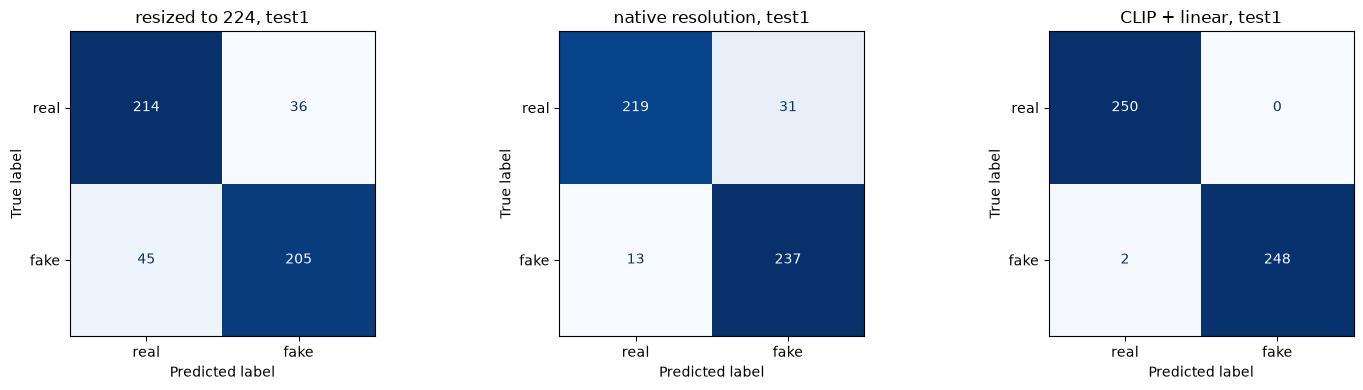

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, mode in zip(axes, NAMES):
    g = preds[(preds["split"] == "test1 NYT / Midjourney") & (preds["model"] == mode)]
    ConfusionMatrixDisplay.from_predictions(g["label"], g["fake"], display_labels=["real", "fake"], cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"{NAMES[mode]}, test1")
plt.tight_layout(); plt.savefig(FIG / "img_confusion.png", dpi=120); plt.show()

**Geriausias yra CLIP + tiesinis klasifikatorius**: test1 99,6 %, test4 82,0 %, test5 75,0 %. Jis lenkia abu MobileNetV2 modelius visuose rinkiniuose ir pasiekia panašiai kaip MiRAGeNews autorių užšaldytas CLIP tipo modelis su tiesiniu sluoksniu (97,6 %, 77,2 % ir 74,2 %). Su nauju generatoriumi ir jis klysta daugiau: test5 rinkinyje pagauna 95,2 % SDXL vaizdų, bet tikrų CNN nuotraukų teisingai palieka tik 54,8 %.

Tarp MobileNetV2 modelių originali raiška vėl geresnė: test1 91,2 % prieš 83,8 %, test4 64,2 % prieš 58,2 %, test5 67,8 % prieš 59,4 %. Taigi smulkios pikselių detalės, kurias sumažinimas ištrina, konvoliuciniam tinklui padeda.

Validacijoje parinktos ribos: CLIP 0,67, originalios raiškos 0,56, sumažinto vaizdo 0,80. Palyginti su riba 0,5, test1 rinkinyje accuracy pakito nuo 0 iki +1,2 punkto. Test4 ir test5 rinkiniuose CLIP pakilo 1,6 ir 2,2 punkto, o sumažinto vaizdo modelis nukrito 1,8 ir 3,2 punkto: riba nepagerina modelio, tik perkelia neaiškius vaizdus iš vienos klasės į kitą.

## 6. Klaidos
Pasirinkto modelio (didžiausias validacijos accuracy) klaidos, kuriose jis buvo labiausiai įsitikinęs: kiekviename testo rinkinyje po dvi tikras nuotraukas, palaikytas sugeneruotomis, ir po du sugeneruotus vaizdus, palaikytus tikrais.

model: CLIP + linear, errors per test set: {'test1 NYT / Midjourney': 2, 'test4 BBC / SDXL': 90, 'test5 CNN / SDXL': 125}


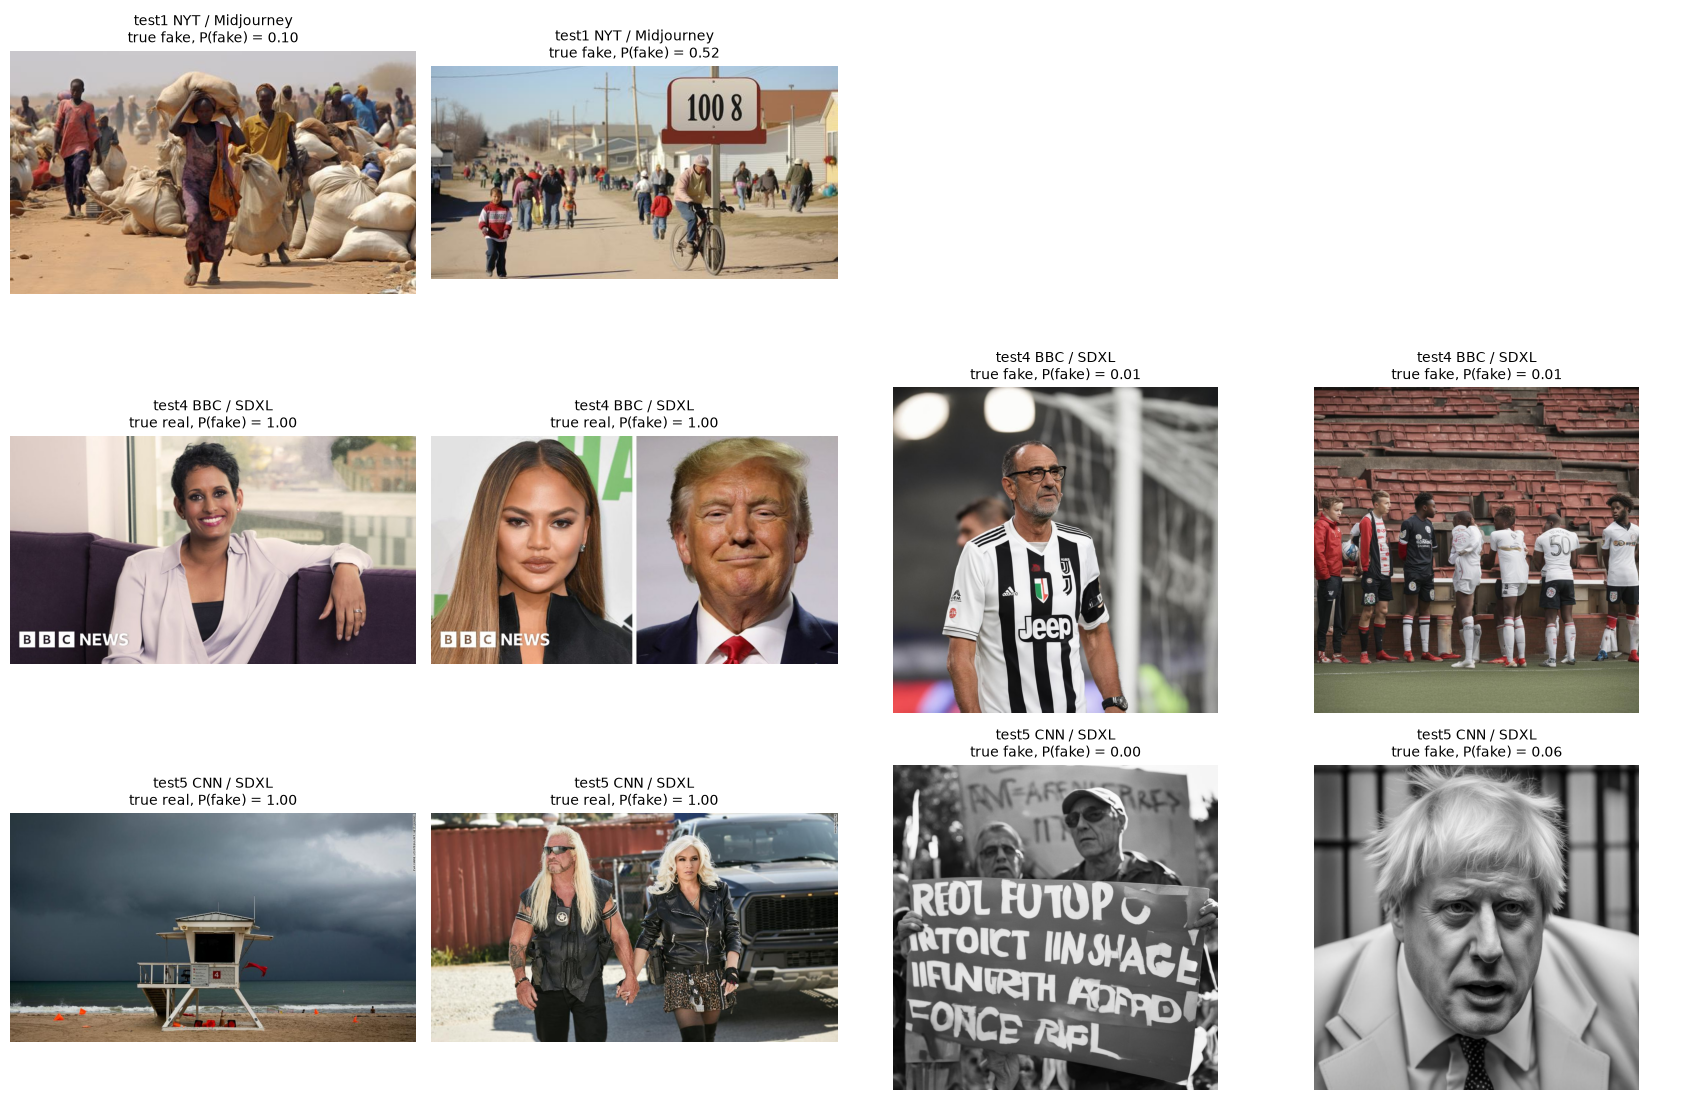

In [14]:
best = table.loc["validation", "accuracy"].idxmax()
wrong = preds[(preds["model"] == best) & (preds["split"] != "validation") & (preds["fake"] != preds["label"])]
wrong = wrong.assign(sureness=(wrong["p_fake"] - cutoff[best]).abs()).sort_values("sureness", ascending=False)
picked = wrong.groupby(["split", "label"], sort=False).head(2).sort_values(["split", "label"])
print(f"model: {NAMES[best]}, errors per test set:", wrong.groupby("split").size().to_dict())

splits = picked["split"].unique()
fig, axes = plt.subplots(len(splits), 4, figsize=(17, 3.7 * len(splits)))
for row, split in zip(axes, splits):  # viena eilute vienam rinkiniui, net jei klaidu maziau nei 4
    for ax in row: ax.axis("off")
    for ax, (_, r) in zip(row, picked[picked["split"] == split].iterrows()):
        ax.imshow(open_rgb(sets[split][0][r["image"]]))
        ax.set_title(f"{split}\ntrue {('real', 'fake')[r['label']]}, P(fake) = {r['p_fake']:.2f}", fontsize=10)
plt.tight_layout(); plt.savefig(FIG / "img_errors.png", dpi=110); plt.show()

Ar modeliai vis dar remiasi JPEG nustatymu? Test4 ir test5 rinkiniuose dalis tikrų nuotraukų išsaugota su lygiai ta pačia JPEG lentele kaip visi sugeneruoti vaizdai (mokymo duomenyse tokių tikrų nuotraukų nėra). Jei modelis remiasi JPEG nustatymu, šias nuotraukas jis dažniau palaikys sugeneruotomis. Lentelėje parodyta, kokią dalį tikrų nuotraukų kiekvienas modelis palaikė sugeneruotomis:

In [15]:
fake_table = jpeg_table(train_x[np.flatnonzero(train_y == 1)[0]])
real = preds[(preds["label"] == 0) & preds["split"].str.startswith(("test4", "test5"))].copy()
same = {name: np.array([jpeg_table(b) == fake_table for b in sets[name][0]]) for name in real["split"].unique()}
real["same JPEG table as fakes"] = [same[s][i] for s, i in zip(real["split"], real["image"])]
flagged = real.pivot_table(index=["split", "same JPEG table as fakes"], columns="model", values="fake", aggfunc="mean")
flagged[list(NAMES)].rename(columns=NAMES).round(3).join(real[real["model"] == "clip"].groupby(["split", "same JPEG table as fakes"]).size().rename("photos"))

resized to 224  native resolution  \
split            same JPEG table as fakes                                      
test4 BBC / SDXL False                              0.152              0.322   
                 True                               0.380              0.646   
test5 CNN / SDXL False                              0.156              0.219   
                 True                               0.188              0.257   

                                           CLIP + linear  photos  
split            same JPEG table as fakes                         
test4 BBC / SDXL False                             0.211     171  
                 True                              0.367      79  
test5 CNN / SDXL False                             0.219      32  
                 True                              0.486     218

Tikros nuotraukos su ta pačia JPEG lentele kaip sugeneruoti vaizdai visų trijų modelių dažniau palaikomos sugeneruotomis, pvz., originalios raiškos modelio test4 rinkinyje 64,6 % prieš 32,2 %. Tačiau šias nuotraukas skiria ne tik JPEG: test4 rinkinyje visos jos yra 624 pikselių pločio, o kitos 1 024 ir platesnės, todėl tai gali būti kitokio tipo BBC nuotraukos. Skirtumas didelis ir CLIP modeliui, kurio įvestis sumažinama iki 224 × 224 (36,7 % prieš 21,1 % ir 48,6 % prieš 21,9 %), todėl vien JPEG nustatymu jo paaiškinti negalima.

### Kas išbandyta

Pirmoje versijoje iš naujo buvo suspaudžiama tik pusė mokymo vaizdų. Kadangi šis skirtumas išliko, buvo išbandyta suspausti kiekvieną vaizdą (Grommelt et al. 2024 taip pašalinus JPEG šališkumą gavo daugiau nei 11 punktų su nematytais generatoriais). Abu MobileNetV2 modeliai apmokyti iš naujo; accuracy su riba 0,5:

| Modelis | Suspaustų iš naujo mokymo vaizdų | Validacija | test1 | test4 | test5 |
|---|---|---|---|---|---|
| Sumažintas vaizdas | 50 % | 84,4 % | 84,6 % | 61,2 % | 64,2 % |
| Sumažintas vaizdas | 100 % | 82,0 % | 82,6 % | 60,0 % | 62,6 % |
| Originali raiška | 50 % | 92,9 % | 90,4 % | 65,2 % | 72,6 % |
| Originali raiška | 100 % | 91,7 % | 90,8 % | 64,4 % | 68,6 % |

Suspaudimas kiekvieno vaizdo nepagerino nė vieno rinkinio daugiau nei 0,4 punkto, o test5 rinkinyje originalios raiškos modelis nukrito 4 punktais. Skirtumas tarp tikrų nuotraukų su netikrų JPEG lentele ir be jos irgi išliko (pirmoje versijoje test4 78 % prieš 47 %). Taigi mūsų duomenyse ne JPEG nustatymas lėmė klaidas su nematytais leidėjais. Didžiausią pagerėjimą davė kitas požymių šaltinis (CLIP), o ne mokymo pakeitimai.

### Dažniausios klaidos

1. **Kitas leidėjas ir kitas generatorius.** CLIP modelis test1 rinkinyje suklysta tik 2 kartus iš 500, test4 - 90, test5 - 125. Daugiausia klaidų yra tikros BBC ir CNN nuotraukos, palaikytos sugeneruotomis (65 ir 113), o ne praleisti SDXL vaizdai (25 ir 12). Modelis išmoko atskirti NYT nuotraukas nuo Midjourney vaizdų, o kitų leidėjų nuotraukos jam dažnai atrodo kaip „ne NYT“, todėl tampa „fake“.
2. **Išblizgintos tikros nuotraukos.** Labiausiai įsitikinęs (P(fake) = 1,00) modelis klysta su tikromis studijos ir įžymybių nuotraukomis: pozuojantys žmonės, švarus apšvietimas, BBC logotipas ant nuotraukos, dviejų portretų koliažas, dramatiškas dangus virš paplūdimio. Būtent taip atrodo daugelis Midjourney vaizdų mokymo duomenyse. Tas pats pastebėta ir pirmoje MobileNetV2 versijoje su sporto ir portretų nuotraukomis.
3. **Sugeneruoti vaizdai, nepanašūs į mokymo netikrus.** Tikrais palaikyti SDXL vaizdai: dvi nespalvotos nuotraukos (protestas su plakatu ir portretas, P(fake) 0,00-0,06) ir sporto scenos (0,01). Plakate raidės akivaizdžiai sujauktos, ką žmogus pastebėtų iškart, bet CLIP požymiai apibūdina vaizdo turinį, o ne raidžių formą. Mokymo duomenyse nespalvoti vaizdai apie 4 kartus dažnesni tarp tikrų nuotraukų nei tarp sugeneruotų, todėl nespalvotas vaizdas modeliui atrodo kaip tikra nuotrauka. Pirmoje MobileNetV2 versijoje tikrais palaikyti ir piešinio, paveikslo ar koliažo stiliaus SDXL vaizdai.
4. **Paprastos sugeneruotos scenos.** Abi test1 klaidos yra sugeneruoti vaizdai: žmonės, nešantys maišus (P(fake) 0,10), ir gatvė su ženklu (0,52, žemiau ribos 0,67). Tai įprastos naujienų scenos be keistų detalių.
5. **Sumažinimas iki 224 × 224.** MobileNetV2 su sumažintais vaizdais test1 rinkinyje suklysta 81 kartą, su originalia raiška 44, nes sumažinant dingsta smulkūs generatoriaus pėdsakai. CLIP irgi mato tik 224 × 224 vaizdą, bet yra geriausias, todėl jam svarbiau ne pikselių detalės, o bendros vaizdo savybės, kurias jis išmoko iš 400 mln. įvairių vaizdų.

## 7. Išvados
Geriausias modelis yra užšaldytas CLIP ViT-L/14 su logistine regresija: Midjourney vaizdus tarp NYT nuotraukų jis atpažįsta 99,6 % tikslumu, o su kitais leidėjais ir SDXL generatoriumi - 82,0 % ir 75,0 %. Geriausias MobileNetV2 (originali raiška) pasiekė 91,2 %, 64,2 % ir 67,8 %, o sumažinus vaizdus iki 224 × 224 rezultatai dar prastesni. Kiekvieno mokymo vaizdo suspaudimas iš naujo ir ribos parinkimas pagal validaciją rezultatų beveik nepakeitė. Visi modeliai su nematytais leidėjais dažniausiai klysta palaikydami tikras nuotraukas sugeneruotomis, todėl norint atpažinti sugeneruotus vaizdus apskritai, mokymo duomenyse reikėtų kelių generatorių ir kelių leidėjų nuotraukų.